# 08 - User Profiling and Segmentation: Are There Really Segments?
**Topic:** Clustering  |  **Reference:** "User Profiling and Segmentation using Python" (amanxai.com, Feb 2024)

**Question.** Can 1,000 social-media users be grouped into meaningful segments for ad targeting?

**Reference method:** pick some columns, scale/one-hot them, run k-means with a chosen k, describe each cluster.
**The trap that method hides:** k-means *always* returns k groups, whether or not the data contain groups. So before profiling anything I ask the question the reference skips: **is there cluster structure at all, or am I describing noise?** I test it three ways (dependence between columns, a clusterability statistic, and a comparison with data that has the same columns but no relationships), then segment anyway and check whether the segments differ on outcomes.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, itertools
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
u = pd.read_csv("../_data/userprof/user_profiles_for_ads.csv")
u.columns = ["id", "age", "gender", "location", "language", "education", "likes", "followed", "device", "hrs_weekday", "hrs_weekend", "ctr", "conv", "ad_secs", "income", "interests"]
print(u.shape, "| missing:", int(u.isna().sum().sum()), "| duplicated users:", int(u.id.duplicated().sum())); u.head(3)

(1000, 16) | missing: 0 | duplicated users: 0


,id,age,gender,location,language,education,likes,followed,device,hrs_weekday,hrs_weekend,ctr,conv,ad_secs,income,interests
0,1,25-34,Female,Suburban,Hindi,Technical,5640,190,Mobile Only,4.5,1.7,0.193,0.067,25,20k-40k,Digital Marketing
1,2,65+,Male,Urban,Hindi,PhD,9501,375,Tablet,0.5,7.7,0.114,0.044,68,0-20k,Data Science
2,3,45-54,Female,Suburban,Spanish,Technical,4775,187,Mobile Only,4.5,5.6,0.153,0.095,80,60k-80k,Fitness and Wellness


## 2. Look at the data first

              count     mean      std    min      25%      50%      75%      max
likes        1000.0  4997.08  2838.49  101.0  2661.25  5002.50  7348.75  9973.00
followed     1000.0   251.44   141.94   10.0   126.00   245.50   377.00   498.00
hrs_weekday  1000.0     2.76     1.28    0.5     1.70     2.80     3.80     5.00
hrs_weekend  1000.0     4.60     2.03    1.0     2.90     4.70     6.40     8.00
ctr          1000.0     0.13     0.07    0.0     0.06     0.13     0.19     0.25
conv         1000.0     0.05     0.03    0.0     0.03     0.05     0.07     0.10
ad_secs      1000.0    91.42    51.50    5.0    45.75    90.00   137.25   179.00

interests per user: {1: 225, 2: 267, 3: 269, 4: 239} | distinct interests: 16


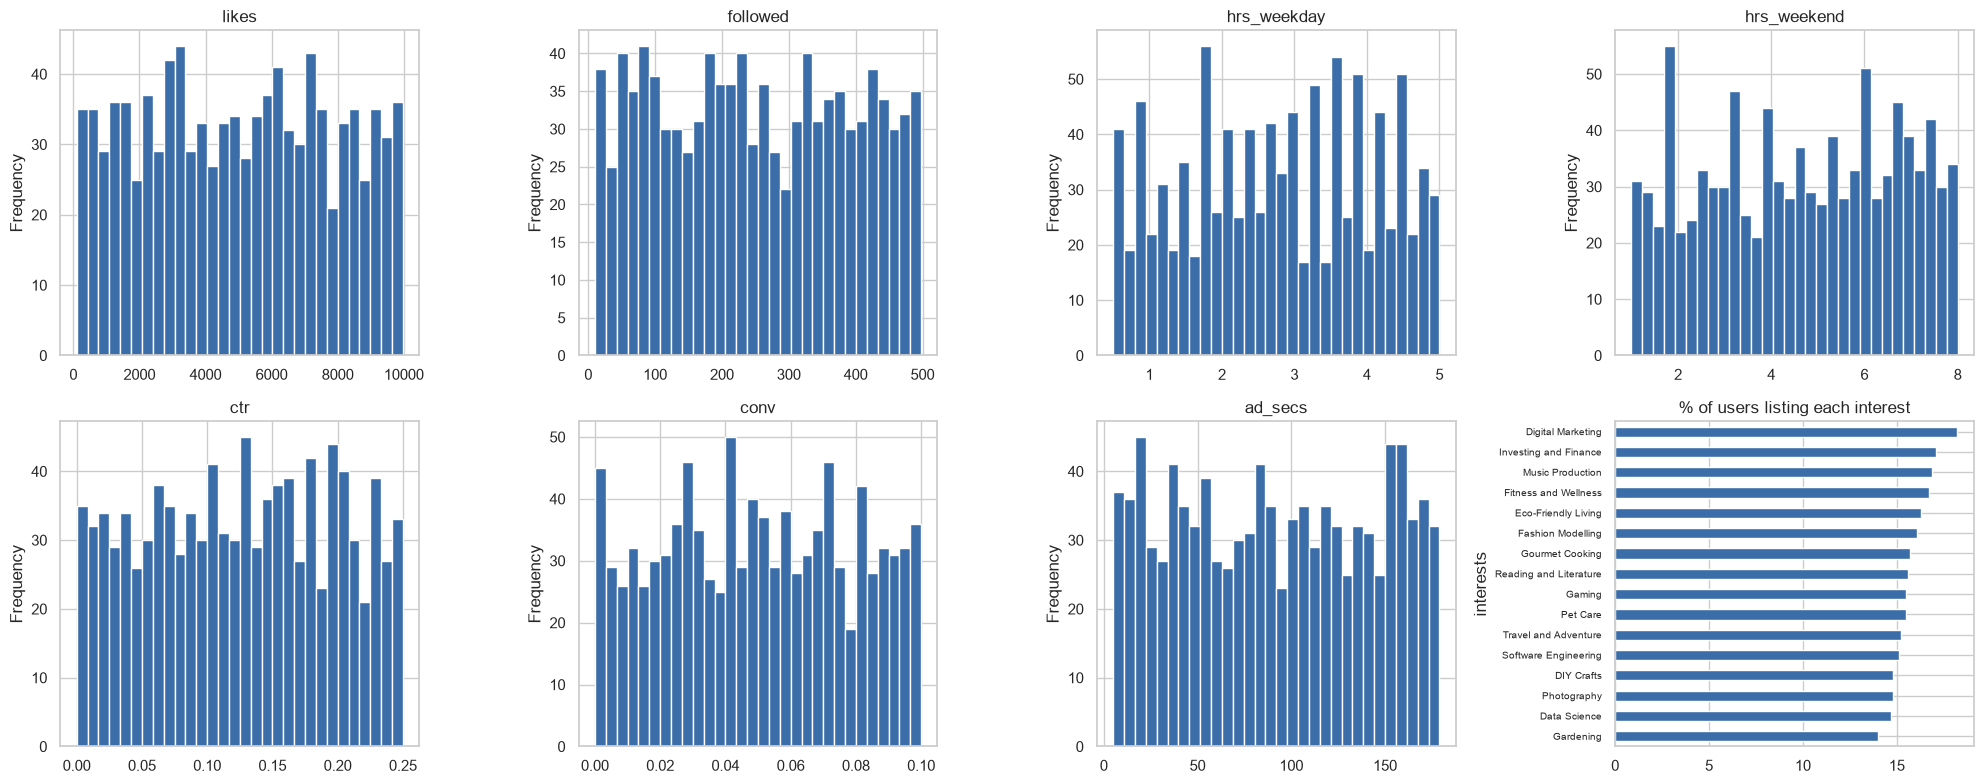

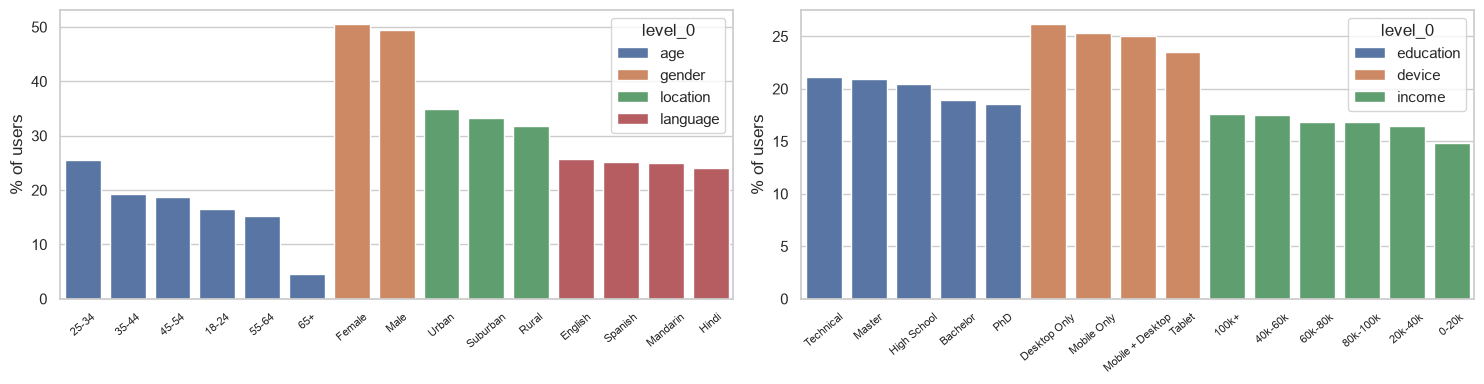

In [2]:
num = ["likes", "followed", "hrs_weekday", "hrs_weekend", "ctr", "conv", "ad_secs"]
cat = ["age", "gender", "location", "language", "education", "device", "income"]
print(u[num].describe().round(2).T.to_string())
inter = u.interests.str.split(", ").explode().str.strip()
print("\ninterests per user:", u.interests.str.split(", ").str.len().value_counts().sort_index().to_dict(), "| distinct interests:", inter.nunique())
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
for a, c in zip(ax.ravel()[:7], num): u[c].plot.hist(bins=30, ax=a, color="#3b6ea8"); a.set_title(c)
(inter.value_counts() / len(u) * 100).sort_values().plot.barh(ax=ax[1, 3], color="#3b6ea8"); ax[1, 3].set_title("% of users listing each interest"); ax[1, 3].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, cs in zip(ax, [cat[:4], cat[4:]]):
    pd.concat({c: u[c].value_counts(normalize=True).mul(100) for c in cs}).rename("pct").reset_index().pipe(lambda d: sns.barplot(data=d, x="level_1", y="pct", hue="level_0", ax=a)); a.set_xlabel(""); a.set_ylabel("% of users"); a.tick_params(axis="x", rotation=40, labelsize=8)
plt.tight_layout(); plt.show()

**Reading it.** Every numeric column looks *flat*: each runs over a clean range (likes 101-9,973; followed accounts 10-498; weekday hours 0.5-5.0; weekend hours 1-8; CTR 0-0.25; conversion 0-0.10; ad time 5-179 seconds), with the mean and median at the middle and the quartiles at about 25% / 75% of the range, which is how a **uniform** distribution looks. Real behaviour data usually shows skew and long tails (a few heavy users). The categorical columns are almost perfectly evenly split (gender 51/49; location 35/33/32; the four languages, four device types and five education levels each 19-26%), and users list 1, 2, 3 or 4 interests in nearly equal numbers (225/267/269/239). Together this is the pattern of **randomly generated columns**, which the next section tests formally. (The source does not document how the file was produced; this is an inference from the shape of the data.)

## 3. Is there structure? Test 1: are any columns related?
Clusters can only exist if variables depend on each other. (a) Correlations among the 7 numeric columns; (b) chi-square tests of independence for every pair of the 7 categorical columns; (c) ANOVA of each numeric column across each categorical one. If columns were independent, the p-values of these tests would be spread **evenly between 0 and 1**; I also correct for the many tests (Benjamini-Hochberg).

numeric columns: largest |correlation| between any two = 0.082
70 tests | raw p < 0.05: 3 (about 4 expected by chance) | after BH correction p_adj < 0.05: 0
 test           x        y     p  p_adj
anova    followed location 0.015  0.725
anova hrs_weekend location 0.039  0.725
anova    followed language 0.044  0.725
anova         ctr language 0.059  0.725
anova         ctr   device 0.068  0.725


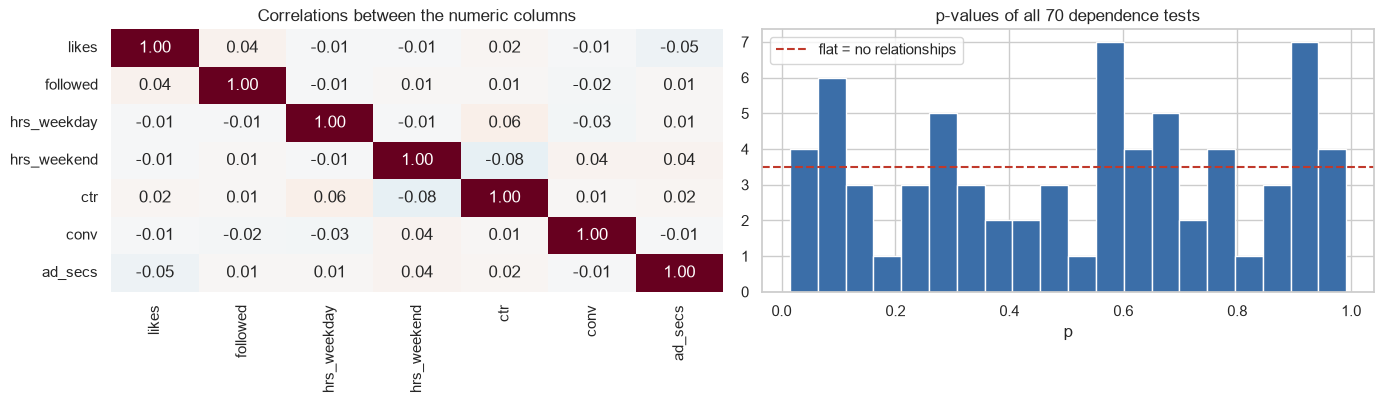

In [3]:
cm = u[num].corr(); off = cm.where(~np.eye(len(cm), dtype=bool)).abs().stack()
print("numeric columns: largest |correlation| between any two = %.3f" % off.max())
pv = []
for a, b in itertools.combinations(cat, 2):
    p = stats.chi2_contingency(pd.crosstab(u[a], u[b]))[1]; pv.append(("chi2", a, b, p))
for n_, c_ in itertools.product(num, cat):
    p = stats.f_oneway(*[g[n_].to_numpy() for _, g in u.groupby(c_)])[1]; pv.append(("anova", n_, c_, p))
P = pd.DataFrame(pv, columns=["test", "x", "y", "p"]); P["p_adj"] = multipletests(P.p, method="fdr_bh")[1]
print(len(P), "tests | raw p < 0.05: %d (about %.0f expected by chance) | after BH correction p_adj < 0.05: %d" % ((P.p < .05).sum(), .05 * len(P), (P.p_adj < .05).sum()))
print(P.sort_values("p").head(5).round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False); ax[0].set_title("Correlations between the numeric columns")
ax[1].hist(P.p, bins=20, color="#3b6ea8"); ax[1].axhline(len(P) / 20, color="#c0392b", ls="--", label="flat = no relationships"); ax[1].set_title("p-values of all %d dependence tests" % len(P)); ax[1].set_xlabel("p"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading it.** The largest correlation between any two numeric columns is 0.08. Among 70 independence tests only 3 reach p < 0.05, about what chance alone gives (3.5 expected), and **none survives multiple-testing correction** (smallest adjusted p = 0.73). The p-value histogram is flat. **The columns are statistically independent of each other** in this file: no combination of attributes goes together, so there is nothing for a clustering algorithm to discover.

## 4. Test 2 and 3: clusterability, and real data vs data with the same columns but no relationships
* **Hopkins statistic** (0.5 = uniformly random points, near 1 = clustered).
* **Null data:** shuffle each column independently. Every column keeps its exact distribution, every relationship between columns is destroyed. I run the same k-means / silhouette search on 30 such shuffles. If the real data's best silhouette is no better than that of the shuffles, k-means is finding nothing but noise.

Hopkins statistic (7 numeric columns): 0.50 | (all 53 encoded columns): 0.54   (0.5 = random)


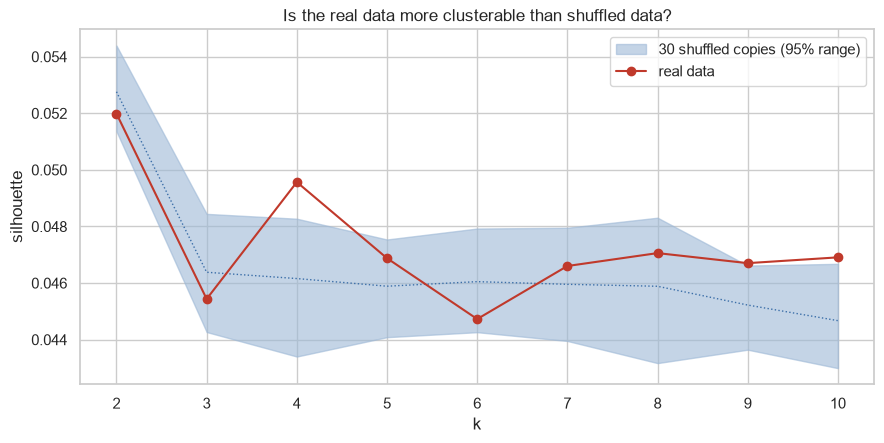

real best silhouette 0.052 at k=2 | shuffled: mean best 0.053 (95% range 0.051-0.054)


In [4]:
inter_cols = sorted(inter.unique()); multi = pd.DataFrame({i: u.interests.str.contains(i, regex=False).astype(int) for i in inter_cols})
def design(d, mh):
    pre = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(sparse_output=False), cat)])
    return np.c_[pre.fit_transform(d[num + cat]), mh.to_numpy()]
Xr = design(u, multi)
def hopkins(X, m=100, seed=0):
    r = np.random.RandomState(seed); idx = r.choice(len(X), m, replace=False); nn = NearestNeighbors(n_neighbors=2).fit(X)
    w = nn.kneighbors(X[idx])[0][:, 1]; U = r.uniform(X.min(0), X.max(0), (m, X.shape[1])); d = nn.kneighbors(U, n_neighbors=1)[0][:, 0]
    return float(d.sum() / (d.sum() + w.sum()))
Xnum = StandardScaler().fit_transform(u[num])
print("Hopkins statistic (7 numeric columns): %.2f | (all %d encoded columns): %.2f   (0.5 = random)" % (np.mean([hopkins(Xnum, seed=s) for s in range(10)]), Xr.shape[1], np.mean([hopkins(Xr, seed=s) for s in range(10)])))
ks = range(2, 11)
def sil_curve(X, seed=0):
    return [silhouette_score(X, KMeans(k, n_init=3, random_state=seed).fit_predict(X)) for k in ks]
real = sil_curve(Xr)
nulls = []
for s in range(30):
    r = np.random.RandomState(s); ud = u.copy()
    for c in num + cat: ud[c] = r.permutation(ud[c].to_numpy())
    mh = multi.apply(lambda col: r.permutation(col.to_numpy()))
    nulls.append(sil_curve(design(ud, mh), seed=s))
nulls = np.array(nulls)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.fill_between(list(ks), np.percentile(nulls, 2.5, 0), np.percentile(nulls, 97.5, 0), color="#9db8d6", alpha=.6, label="30 shuffled copies (95% range)"); ax.plot(list(ks), nulls.mean(0), color="#3b6ea8", lw=1, ls=":")
ax.plot(list(ks), real, "o-", color="#c0392b", label="real data"); ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.set_title("Is the real data more clusterable than shuffled data?"); ax.legend(); plt.tight_layout(); plt.show()
print("real best silhouette %.3f at k=%d | shuffled: mean best %.3f (95%% range %.3f-%.3f)" % (max(real), list(ks)[int(np.argmax(real))], nulls.max(1).mean(), *np.percentile(nulls.max(1), [2.5, 97.5])))

**Reading it.**
* Hopkins statistic 0.50 on the numeric columns (exactly "random") and 0.54 on all 53 encoded columns.
* The best silhouette score of the real data (0.052) sits **inside** the range obtained from 30 shuffled copies (0.051-0.054; mean 0.053). The red line (real) cannot be told apart from the blue band (noise) at any k.
* A silhouette near 0.05 is essentially zero: points are not closer to their own cluster than to others. There is no cluster structure beyond what k-means imposes on noise.

## 5. Segment anyway (the reference's step) and test whether the segments are stable and different
k-means with k = 5 on the same encoded features. Then: (a) stability under bootstrap resampling, (b) do segments differ on the **outcome** columns CTR and conversion rate? (these are in the clustering input, so any difference is partly built in; I compare with the same procedure on a shuffled copy to see how much of it is just k-means splitting noise).

In [5]:
K = 5
km = KMeans(K, n_init=10, random_state=0).fit(Xr); lab = km.labels_
aris = []
for s in range(20):
    idx = np.random.RandomState(s).choice(len(Xr), len(Xr), replace=True); l2 = KMeans(K, n_init=3, random_state=s).fit(Xr[idx]).predict(Xr); aris.append(adjusted_rand_score(lab, l2))
print("segment sizes:", np.bincount(lab).tolist(), "| bootstrap stability (ARI vs full fit): mean %.2f, min %.2f" % (np.mean(aris), np.min(aris)))
def eta2(x, l):
    g = [x[l == k] for k in np.unique(l)]; ssb = sum(len(a) * (a.mean() - x.mean()) ** 2 for a in g); return ssb / ((x - x.mean()) ** 2).sum()
rows = []
for c in ["ctr", "conv", "ad_secs", "hrs_weekday"]:
    x = u[c].to_numpy(float); real_e = eta2(x, lab); nul = []
    for s in range(30):
        r = np.random.RandomState(100 + s); ud = u.copy()
        for cc in num + cat: ud[cc] = r.permutation(ud[cc].to_numpy())
        mh = multi.apply(lambda col: r.permutation(col.to_numpy())); ln = KMeans(K, n_init=3, random_state=s).fit_predict(design(ud, mh)); nul.append(eta2(ud[c].to_numpy(float), ln))
    rows.append([c, real_e, np.mean(nul), np.percentile(nul, 95), stats.kruskal(*[x[lab == k] for k in range(K)])[1]])
eff = pd.DataFrame(rows, columns=["variable", "eta2_real_segments", "eta2_shuffled_mean", "eta2_shuffled_95th", "kruskal_p"]).set_index("variable")
print(eff.round(4).to_string())

segment sizes: [190, 210, 207, 186, 207] | bootstrap stability (ARI vs full fit): mean 0.25, min 0.09


             eta2_real_segments  eta2_shuffled_mean  eta2_shuffled_95th  kruskal_p
variable                                                                          
ctr                      0.4563              0.2554              0.4797        0.0
conv                     0.1154              0.3025              0.4675        0.0
ad_secs                  0.3011              0.2521              0.4795        0.0
hrs_weekday              0.2872              0.2673              0.4642        0.0


**Reading it.**
* k-means with k = 5 returns five tidy segments of 186-210 users: it would have returned five for any data.
* **They are not stable:** refitting on bootstrap resamples and comparing with the original gives an adjusted Rand index of only 0.25 on average (worst 0.09; 1 would be identical). Re-running the analysis would give different segments.
* The Kruskal-Wallis p-values are 0.0, but that is circular: the segments were built from these same columns, so they must differ on them. The fair comparison is with the same procedure on shuffled data: the segments' effect sizes (eta-squared 0.46 for CTR, 0.12 for conversion, 0.30 for ad time, 0.29 for weekday hours) fall **within the range k-means produces from pure noise** (shuffled 95th percentile about 0.46-0.48; for conversion the real value is even below the shuffled average). The segments do not separate users more than random splitting does.

         users    ctr   conv  ad_secs  hrs_weekday  hrs_weekend     likes  followed                                                  top_interests
segment                                                                                                                                           
0          190  0.110  0.034  127.074        3.756        4.865  5845.179   347.558  Fitness and Wellness, Gourmet Cooking, Reading and Literature
1          210  0.189  0.056  112.419        3.049        4.837  3216.076   150.019     Digital Marketing, Music Production, Investing and Finance
2          207  0.062  0.043   71.850        2.723        4.468  4955.121   121.005  Digital Marketing, Fitness and Wellness, Software Engineering
3          186  0.093  0.061  100.151        1.576        5.790  4465.167   358.054      Fashion Modelling, Eco-Friendly Living, Digital Marketing
4          207  0.168  0.055   49.140        2.641        3.186  6545.377   300.734                    Data Science, G

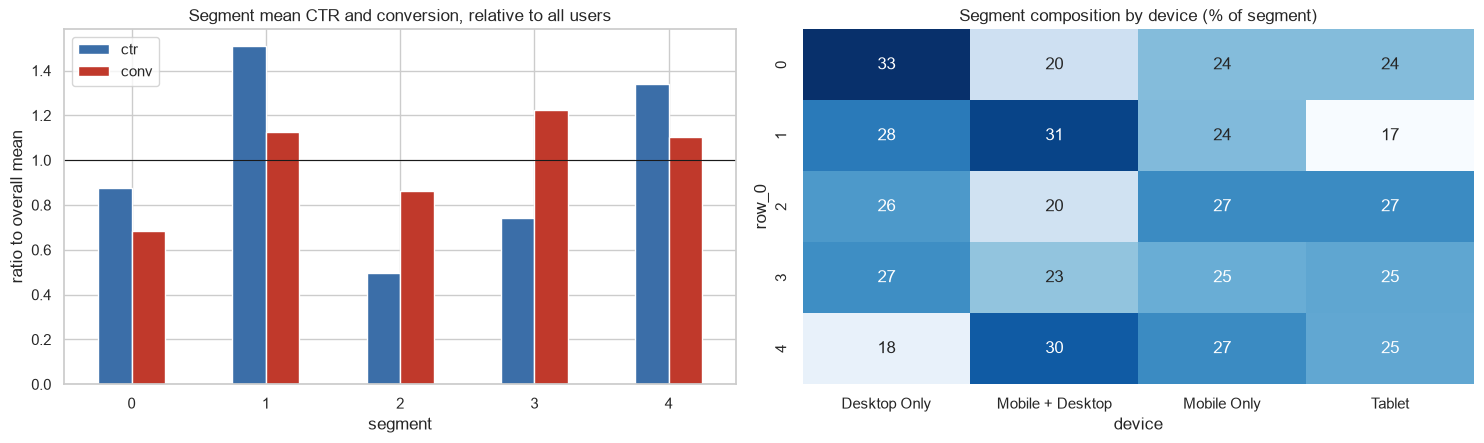

In [6]:
prof = u.assign(segment=lab).groupby("segment").agg(users=("id", "size"), ctr=("ctr", "mean"), conv=("conv", "mean"), ad_secs=("ad_secs", "mean"), hrs_weekday=("hrs_weekday", "mean"), hrs_weekend=("hrs_weekend", "mean"), likes=("likes", "mean"), followed=("followed", "mean")).round(3)
top = {k: ", ".join(multi[lab == k].mean().sort_values(ascending=False).head(3).index) for k in range(K)}
prof["top_interests"] = pd.Series(top)
print(prof.to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
(prof[["ctr", "conv"]] / u[["ctr", "conv"]].mean()).plot.bar(ax=ax[0], color=["#3b6ea8", "#c0392b"]); ax[0].axhline(1, color="k", lw=.8); ax[0].set_title("Segment mean CTR and conversion, relative to all users"); ax[0].set_ylabel("ratio to overall mean"); ax[0].tick_params(axis="x", rotation=0)
sns.heatmap(pd.crosstab(lab, u.device, normalize="index") * 100, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax[1]); ax[1].set_title("Segment composition by device (% of segment)")
plt.tight_layout(); plt.show()

**Reading it.** The profile table looks like a report an analyst could present: segment 1 has CTR 0.19 and likes marketing/music, segment 2 CTR 0.06, segment 4 weekend hours of only 3.2... Segments differ visibly, and it would be easy to write a persona for each ("high-CTR digital-marketing fans"). But we just saw that these differences are what k-means does to noise, that the segments change on resampling, and (next section) that no attribute predicts the outcomes. **Any persona written from this table would be a story about noise.** This is the danger of the reference approach: nothing in k-means warns you.

## 6. A defensible alternative: test candidate rules against the outcome
If clusters are not real, segment by a **rule you can validate**: does CTR or conversion differ across any single existing attribute (device, age, income, interest...)? Kruskal-Wallis across groups, corrected for multiple testing.

In [7]:
rows = []
for c in cat:
    for o in ["ctr", "conv", "ad_secs"]:
        rows.append([c, o, stats.kruskal(*[g[o].to_numpy() for _, g in u.groupby(c)])[1]])
for i in inter_cols:
    for o in ["ctr", "conv", "ad_secs"]:
        rows.append([f"interest: {i}", o, stats.mannwhitneyu(u.loc[multi[i] == 1, o], u.loc[multi[i] == 0, o])[1]])
R = pd.DataFrame(rows, columns=["attribute", "outcome", "p"]); R["p_adj"] = multipletests(R.p, method="fdr_bh")[1]
print(len(R), "tests | raw p<0.05:", int((R.p < .05).sum()), "(chance would give about %.0f)" % (.05 * len(R)), "| after correction:", int((R.p_adj < .05).sum()))
print(R.sort_values("p").head(6).round(3).to_string(index=False))

69 tests | raw p<0.05: 1 (chance would give about 3) | after correction: 0
                       attribute outcome     p  p_adj
interest: Reading and Literature     ctr 0.017  0.924
                        language     ctr 0.061  0.924
                          device     ctr 0.062  0.924
  interest: Fitness and Wellness    conv 0.064  0.924
          interest: Data Science     ctr 0.162  0.924
            interest: DIY Crafts    conv 0.167  0.924


**Reading it.** Out of 69 tests of attribute vs outcome, 1 reaches p < 0.05 (chance would give about 3) and **none survives correction** (smallest adjusted p = 0.92). No single attribute (device, age, income, language, interest...) is related to CTR, conversion or ad-interaction time. For this data set the honest recommendation is *no targeting rule*: whatever differences there are lie within chance. With real data one would expect some of these tests to be significant.

## 7. Save (with the honest caveat attached)

In [8]:
pre_fit = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(sparse_output=False), cat)]).fit(u[num + cat])
joblib.dump({"pre": pre_fit, "kmeans": km, "interest_cols": inter_cols, "K": K}, "model/segmenter.joblib")
meta = {"num": num, "cat": cat, "cat_values": {c: sorted(u[c].unique().tolist()) for c in cat}, "ranges": {c: [float(u[c].min()), float(u[c].max())] for c in num}, "defaults": {c: float(u[c].median()) for c in num},
        "interest_cols": inter_cols, "profile": prof.reset_index().astype(str).to_dict("records"), "bootstrap_ARI_mean": float(np.mean(aris)),
        "real_best_silhouette": float(max(real)), "null_best_silhouette_mean": float(nulls.max(1).mean()), "caveat": "Segments are not statistically distinct from a shuffled null: use for illustration only."}
json.dump(meta, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['meta.json', 'segmenter.joblib']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Method | k-means on chosen columns, describe clusters | first test whether structure exists, then cluster, then test the clusters |
| Dependence between columns | not checked | largest correlation 0.08; 0 of 70 tests survive correction |
| Clusterability | not checked | Hopkins 0.50; best silhouette 0.052 = shuffled-data range |
| Stability | not checked | bootstrap ARI 0.25 (unstable) |
| Segment value | "personalised campaigns" | segments' effect sizes are inside the null range; no rule predicts CTR/conversion |

**What I learned.** (1) k-means always returns k clusters: a result is not evidence of structure. (2) Shuffle each column independently to create a *null data set*, and see whether your score beats it. (3) Check stability by resampling before naming segments. (4) Test any proposed segment on an outcome it was *not* built from, with multiple-testing correction.

**Limits.** The file appears to be randomly generated (inferred from the flat distributions and zero dependence), so the negative result is about this file; real user data usually has structure. The tests used are standard but not exhaustive (for example, non-linear dependence between numeric columns was not examined beyond what k-means itself would find). **Next step:** repeat the same pipeline on real behavioural data, where I would expect the null comparison to show a clear gap.